In [2]:
import pathlib

ROOT = pathlib.Path.cwd().parent

# Lattice surgery in Stim: measuring $Z_A Z_B$ between two surface-code patches
## 1. Problem

The rotated surface code stores one logical qubit in a $d_1 \times d_2$ grid of data qubits. Commuting Pauli checks of weight 2 or 4 are measured on the faces of the grid, and the code space is a joint eigenspace of all the checks. The sign of each check is fixed by its first measurement and then tracked in software, so up to relabelling we can take every sign to be $+1$.


<img src="../figures/patch_d3.png" width="200">


*Figure 1. A $3 \times 3$ patch. Logical $Z_L$ is a column of Z's, logical $X_L$ a row of X's. (Figure drawn with AI assistance from the package's `check_patch` output.)*

We start with two $d \times d$ patches encoding logical qubits $A$ and $B$, with logical operators $Z_A$ and $Z_B$. We want to measure the product $Z_A Z_B$ without measuring $Z_A$ or $Z_B$ individually. Measuring the product reveals only the parity of the two qubits, so a state such as $\alpha|00\rangle + \beta|11\rangle$ keeps its superposition. Measuring the two operators separately would collapse it. This parity measurement is the basic two-qubit operation between surface-code patches; a logical CNOT can be built from it. Lattice surgery (Horsman et al., arXiv:1111.4022, §3 and §7.1) performs it by merging and then splitting the patches, as we explain below.

## 2. Why the merge measures $Z_A Z_B$

Given the two patches as above, we explain why the merge measures $Z_A Z_B$. We put $d$ seam qubits in a column between the patches, reset them to $|+\rangle$, and merge the two patches into a single $(2d+1) \times d$ patch $M$, as shown in the following figure.

<img src="../figures/merge_d3.png" width="400">

Comparing the checks of $M$ with those of $A$ and $B$, there are $d-1$ grown checks, all of type $X$, and $d+1$ new checks, all of type $Z$; every other check is unchanged.

Let $V_{old} = V_A \otimes V_s \otimes V_B$ be the code space of $S_A \otimes S_s \otimes S_B$, where $S_s$ is generated by $X$ on each seam qubit, and let $v_{old} \in V_{old}$ be the state of the two patches and the seam. Measuring an unchanged check returns its old value, and so does measuring a grown check, since it is an old check times $X_s X_{s'}$ on two seam qubits, which is $+1$ on $|+\rangle|+\rangle$. Each new check, on its own, anticommutes with $X_s$ on a seam qubit, so its outcome is uniformly random and carries no information about $A$ and $B$. Their product, however, is $Z_A Z_B$, with $Z_A$ on column $d-1$ and $Z_B$ on column $d+1$: each seam qubit lies in exactly two new checks, so its $Z$ cancels. Therefore measuring the checks of $M$ measures $Z_A Z_B$ and nothing else. One of the two qubits' worth of degrees of freedom is fixed, and the remaining one survives coherently as the logical qubit of the merged code (see [lattice_surgery_summary.pdf](../docs/lattice_surgery_summary.pdf)).


## 3. Implementing the geometry

We implement the geometry of surface codes in `patch.py`. Data qubits sit at integer points $(x, y)$. Each check lives on a unit face, named by its lower-left corner, with its ancilla at the centre of the face. A face is an $X$ check when $x + y$ is even and a $Z$ check when it is odd; weight-2 faces are kept only on the left and right edges ($X$) and the top and bottom edges ($Z$). `check_patch` returns the checks of a patch as `Check` named tuples recording the ancilla position, type, corners and weight, and `logical_z`, `logical_x` return the supports of the logical operators: a column and a row of data qubits.

In [9]:
from lattice_surgery_stim.patch import check_patch

# check the number of stabilizers in each patch
p_A = check_patch(0, 0, 3, 3)
p_B = check_patch(4, 0, 3, 3)
p_M = check_patch(0, 0, 7, 3)
assert len(p_A) == 8
assert len(p_B) == 8
assert len(p_M) == 20
print(len(p_A), len(p_B), len(p_M))

8 8 20


## 4. Circuits

We build the circuits of the experiments using Stim, which is equipped with nice tools like detectors and observables. Each round measures every check through an ancilla with four CNOT layers, in the order lower-left, upper-left, lower-right, upper-right for $X$ checks and lower-left, lower-right, upper-left, upper-right for $Z$ checks. Data qubits are reset to $|0\rangle$. Noise of strength $p$ follows every operation: depolarizing noise after gates and on idle data qubits, and flips after resets and before measurements. Detectors compare each check with its value in the previous round.

The idle circuit tracks $Z_A$ and $Z_B$ as observables. The surgery circuit tracks three: the parity $\prod_j n_j = Z_A Z_B$ from the new checks, and $Z_A$, $Z_B$ at the final readout. It has three phases.

1. **Before the merge**, $d$ rounds: the checks of $A$ and $B$ are measured separately, exactly as in the idle circuit.
2. **Merged**, $d$ rounds: the seam qubits are reset to $|+\rangle$ and the checks of the merged patch $M$ are measured. The $d+1$ new $Z$ checks have random first outcomes, so they get no detector in their first round; their product in that round is the observable $Z_A Z_B$. The grown $X$ checks are compared with their old values as usual.
3. **Split**, $d$ rounds: the seam qubits are measured in the $X$ basis and the checks of $A$ and $B$ are measured separately again. A grown check shrinks back, so its first detector after the split also includes the two seam outcomes it lost. The new $Z$ checks disappear.

At the end all data qubits are read out in the $Z$ basis, which gives a final detector for each $Z$ check and the observables $Z_A$ and $Z_B$. Fewer than $d$ merged rounds lets repeated measurement errors on a new check flip the parity undetected, as the distance check below shows, so we merge for $d$ rounds. For a fair comparison the idle patches also run for $3d$ rounds.

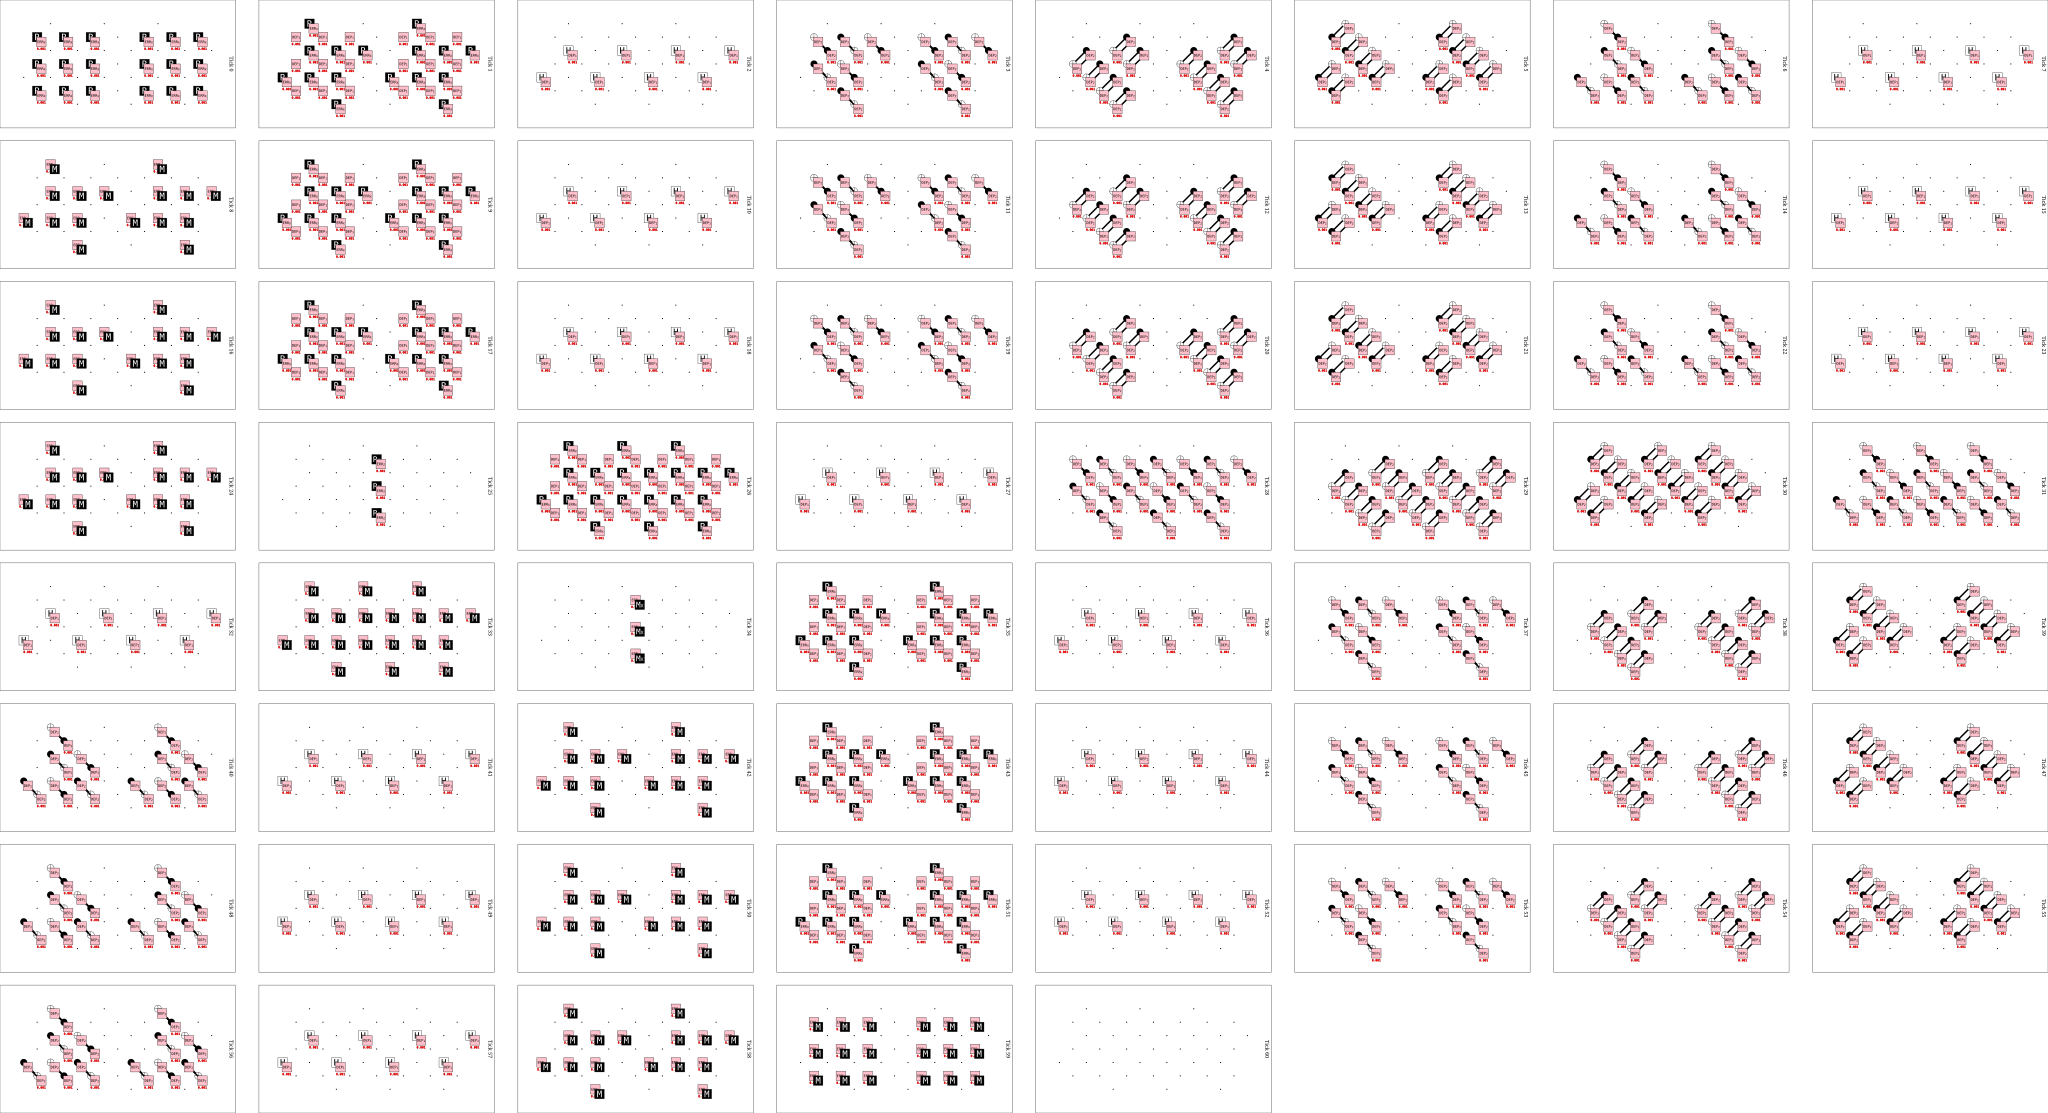

In [13]:
from lattice_surgery_stim.merge import merge_circuits

# d = 3, one merged round (to keep the picture small), p = 0.001
c = merge_circuits(3, 1, 0.001)
c.diagram("timeslice-svg")

In [ ]:
# shortest undetectable logical error (fault distance) for m = 1..5 merged rounds at d = 5
for m in range(1, 6):
    print(len(merge_circuits(5, m, 0.001).shortest_graphlike_error()))

1
2
3
4
5


## 5. Experiment

We compare the surgery circuit against two idle patches. Both run for $3d$ rounds; in the surgery circuit the middle $d$ rounds are merged. We take $100{,}000$ shots for each $d = 3, 5$ and $p = 0.002, 0.004, 0.006$, and decode with PyMatching; the sweep is `scripts/experiment.py`. A shot fails when the decoder mispredicts an observable, and we record three failure counts:

- **surgery ZZ**: the $Z_A Z_B$ observable is wrong;
- **surgery any**: at least one of the three observables $Z_A Z_B$, $Z_A$, $Z_B$ is wrong;
- **idle any**: $Z_A$ or $Z_B$ is wrong in the idle circuit.

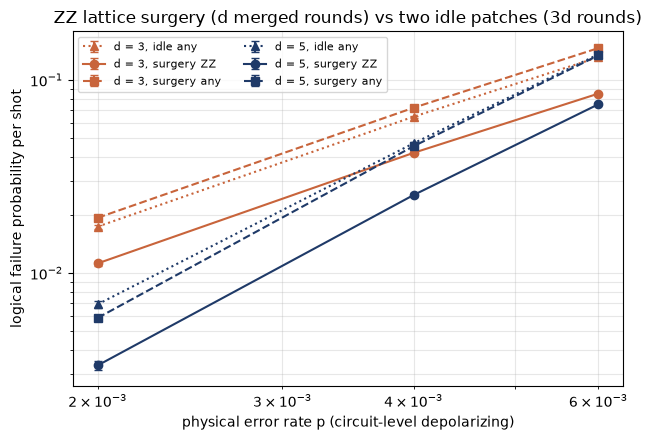

In [14]:
# Plot written with AI assistance (see README).
import pathlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = pathlib.Path.cwd().parent
df = pd.read_csv(ROOT / "results" / "surgery_vs_idle.csv")
df["rate"] = df["failures"] / df["shots"]
df["err"] = np.sqrt(
    df["rate"] * (1 - df["rate"]) / df["shots"]
)  # binomial standard error

styles = {
    "surgery ZZ": {"marker": "o", "linestyle": "-"},
    "surgery any": {"marker": "s", "linestyle": "--"},
    "idle any": {"marker": "^", "linestyle": ":"},
}
colors = {3: "#c8643b", 5: "#1F3A68"}

fig, ax = plt.subplots(figsize=(6.5, 4.5))
for (d, kind), g in df.groupby(["d", "kind"]):
    g = g.sort_values("p")
    ax.errorbar(
        g["p"],
        g["rate"],
        yerr=g["err"],
        color=colors[d],
        label=f"d = {d}, {kind}",
        capsize=3,
        **styles[kind],
    )
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("physical error rate p (circuit-level depolarizing)")
ax.set_ylabel("logical failure probability per shot")
ax.set_title("ZZ lattice surgery (d merged rounds) vs two idle patches (3d rounds)")
ax.legend(fontsize=8, ncol=2)
ax.grid(True, which="both", alpha=0.3)
fig.tight_layout()
fig.savefig(ROOT / "results" / "surgery_vs_idle.png", dpi=200)
plt.show()

At $p = 0.002$ every failure rate at $d = 5$ is about a third of its value at $d = 3$, so the larger code helps, as expected below threshold. At $p = 0.006$ the two distances nearly coincide, so the crossing is a little above $0.006$; we do not have enough points to locate it. The surgery fails about $10\%$ more often than the idle patches at $d = 3$ and about as often at $d = 5$, so measuring $Z_A Z_B$ costs little beyond storing the two qubits for the same time. A possible reason, which we did not test: during the merged rounds an $X$ error chain that flips $Z_A$ has to cross the merged width $2d+1$ instead of $d$.

## 6. Resources

The surgery uses $2(2d+1)d - 1$ qubits (data, seam and one ancilla per check of the merged patch) and $3d$ rounds, of which the $d$ merged rounds are the cost of the measurement in time. Gates: reset and measurement in the $Z$ basis, reset and measurement of the seam in the $X$ basis, H and CNOT, with four CNOT layers per round. Each point uses $100{,}000$ shots.

## 7. Limitations

- Only the smooth merge, which measures $Z_A Z_B$, is implemented. The rough merge, which measures $X_A X_B$, is the same construction with the two check types exchanged.
- Only $Z$-basis preparation and readout are simulated. The experiment therefore tests that the parity outcome is correct and that $Z_A$ and $Z_B$ survive the merge and the split, but not that the coherence of $X_A X_B$ is preserved. That needs a second run with the patches prepared in $|+\rangle$.
- The noise is uniform depolarizing noise with a single strength $p$.
- Only $d = 3, 5$ and three values of $p$ were run, so no threshold is claimed, and the explanation offered for the surgery matching the idle patches at $d = 5$ is untested.
